In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

In [59]:
from google.colab import files

uploaded = files.upload()

Saving PDS EU-DATASET.xlsx to PDS EU-DATASET (1).xlsx


In [60]:
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name, dtype=str, keep_default_na=False, na_values=[""])
df.shape

(31152, 30)

In [61]:
df.shape

(31152, 30)

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31140 entries, 0 to 31151
Data columns (total 45 columns):
 #   Column                                Non-Null Count  Dtype              
---  ------                                --------------  -----              
 0   Alert/risk level                      31140 non-null  object             
 1   Type of public                        31140 non-null  object             
 2   Alert number                          31140 non-null  object             
 3   Alert submitted by                    31140 non-null  object             
 4   Country of origin                     31140 non-null  object             
 5   Is the product counterfeit            31140 non-null  object             
 6   Alert/risk type                       31140 non-null  object             
 7   Risk legal provision                  30266 non-null  object             
 8   Product type                          31140 non-null  object             
 9   Product name          

**1- What is a row?**
After looking into the first 5 rows of our dataset we can see that each row tells us about the safety alert of the product received in EU countries. If we look into the second row of our dataset we can see that safety alert was reported by consumer from United Kingdom(UK) in which he mentioned the product type as toothpaste and type of risk was chemical. (to be continued)

In [63]:
df.head()

,Alert/risk level,Type of public,Alert number,Alert submitted by,Country of origin,Is the product counterfeit,Alert/risk type,Risk legal provision,Product type,Product name,Product description,Product brand,Product category,Product model and/or type,OECD Portal category,Alert/risk description,Technical defect,Other countries with similar alerts,URL of the product recall,URL of the RAPEX data,Product barcode,Product batch number,Product recall code,Product production date,Product packaging description,Alert date (week),Alert modification date (week),URL of main product image,URL of other product images,Measures taken in submitting country
0,Serious risk,Consumer,SR/01140/25,Italy,Unknown,Unknown,Chemical,The product does not comply with the Cosmetic ...,Deodorant,Woody,"Spray deodorant, 150 ml.",INTESA,Cosmetics,NaN,53000000 - Beauty / Personal care / Hygiene,"According to the list of ingredients, the prod...",Type of economic operator to whom the measure(...,NaN,NaN,https://ec.europa.eu/safety-gate-alerts/screen...,8003510002740,ED120431,NaN,NaN,Aluminium can.,2025-03-28,2025-03-27T13:29:08+05:00,https://ec.europa.eu/safety-gate-alerts/public...,NaN,Measures ordered by public authorities (to: Di...
1,Serious risk,Consumer,SR/01136/25,United Kingdom in respect of Northern Ireland,People's Republic of China,Unknown,Chemical,The product does not comply with the Cosmetic ...,Toothpaste,DIAMOND WHITE,"Toothpaste, 96 g.",Home Teeth Whitening,Cosmetics,NaN,53000000 - Beauty / Personal care / Hygiene,The product has an excessive concentration of ...,Type of economic operator to whom the measure(...,NaN,NaN,https://ec.europa.eu/safety-gate-alerts/screen...,659675851839,202501,NaN,NaN,Cardboard box.,2025-03-28,2025-03-25T21:36:02+05:00,https://ec.europa.eu/safety-gate-alerts/public...,NaN,Measures ordered by public authorities (to: Im...
2,Serious risk,Consumer,SR/01197/25,Italy,Unknown,Unknown,Chemical,The product does not comply with the Cosmetic ...,Body cream,PELLI MATURE,"Body cream, advertised as containing vitamin B5.",CERA DI CUPRA,Cosmetics,NaN,53000000 - Beauty / Personal care / Hygiene,"According to the list of ingredients, the prod...",Type of economic operator to whom the measure(...,NaN,NaN,https://ec.europa.eu/safety-gate-alerts/screen...,8002140051104,TED16T,NaN,NaN,Cardboard box.,2025-04-04,2025-03-27T16:22:24+05:00,https://ec.europa.eu/safety-gate-alerts/public...,https://ec.europa.eu/safety-gate-alerts/public...,Measures ordered by public authorities (to: Di...
3,Serious risk,Consumer,SR/01218/25,Italy,Italy,Unknown,Chemical,The product does not comply with the Cosmetic ...,Shampoo and shower foam,Anima Double Sport,"Cosmetic set, consisting of a shampoo and a sh...",Fit You soul,Cosmetics,NaN,53000000 - Beauty / Personal care / Hygiene,"According to the list of ingredients, the prod...",Type of economic operator to whom the measure(...,NaN,NaN,https://ec.europa.eu/safety-gate-alerts/screen...,8054633832646\n8054633837429,20001 200218\n20002 280818,NaN,NaN,Cardboard box.,2025-04-04,2025-03-28T14:30:44+05:00,https://ec.europa.eu/safety-gate-alerts/public...,https://ec.europa.eu/safety-gate-alerts/public...,Measures ordered by public authorities (to: Di...
4,Serious risk,Consumer,SR/01202/25,Italy,Italy,Unknown,Chemical,The product does not comply with the Cosmetic ...,Eau de toilette,ORIGINAL,"Eau de toilette, 100 ml.",DENIM,Cosmetics,NaN,53000000 - Beauty / Personal care / Hygiene,"According to the list of ingredients, the prod...",Type of economic operator to whom the measure(...,NaN,NaN,https://ec.europa.eu/safety-gate-alerts/screen...,7640129895212,NaN,NaN,NaN,Cardboard box.,2025-04-04,2025-03-27T16:27:13+05:00,https://ec.europa.eu/safety-gate-alerts/public...,https://ec.europa.eu/safety-gate-alerts/public...,Measures ordered by public authorities (to: Re...


In [64]:
df["Alert date (week)"].min(), df["Alert date (week)"].max()  # first and last alert date (text sorts fine in YYYY-MM-DD)

('2015-01-09', '2026-09-25')

In [65]:
df.isna().sum().sort_values(ascending=False)  # missing values per column, worst first

,0
URL of the product recall,28678
Product recall code,28435
Product production date,26422
Other countries with similar alerts,21619
Product barcode,19043
Product batch number,18681
Product packaging description,16121
Technical defect,14031
URL of other product images,9611
Alert modification date (week),9447



The two date columns are text. Turn them into real dates.
`format="%Y-%m-%d"` means year-month-day, so there is no day/month mix up.

In [66]:
df["alert_date"] = pd.to_datetime(df["Alert date (week)"], format="%Y-%m-%d")
df["alert_year"] = df["alert_date"].dt.year
df["alert_modified_utc"] = pd.to_datetime(df["Alert modification date (week)"], utc=True)

df[["alert_date", "alert_year", "alert_modified_utc"]].dtypes

,0
alert_date,datetime64[ns]
alert_year,int32
alert_modified_utc,"datetime64[ns, UTC]"


**3-TimeFrame**
The EU safety guard uploads data on weekly basis so the data we are using in this project ranges from the beginning of 2015 to sep 2026.

In [67]:
df["alert_year"].value_counts().sort_index()  # alerts per year (2026 is not a full year)

,count
alert_year,
2015,1855
2016,1873
2017,2020
2018,2047
2019,2153
2020,2213
2021,2104
2022,2099
2023,3341


In [68]:
df.duplicated().sum()  # exact copies of a whole row

np.int64(0)

**1- What is a row?**
In our dataset alert number was treated as unique column but after checking the duplication we realized that there are 12 alert number which were found repeated. This highlights that not all rows represent the unique safety alerts.

In [69]:
df["Alert number"].duplicated().sum()  # same alert number used again

np.int64(12)

In [70]:
repeated = df[df["Alert number"].duplicated(keep=False)]   # keep=False shows ALL rows of a repeated number
repeated.sort_values("Alert number")[["Alert number", "Alert modification date (week)", "Measures taken in submitting country"]].head(6)

,Alert number,Alert modification date (week),Measures taken in submitting country
30577,SR/03784/24,2025-01-03T04:01:02+05:00,Measures ordered by economic operators (to: Re...
2692,SR/03784/24,2025-01-03T04:01:02+05:00,Measures ordered by economic operators (to: Re...
7263,SR/03802/24,2024-12-19T20:58:00+05:00,Measures ordered by economic operators (to: Di...
12158,SR/03802/24,2024-12-19T20:58:00+05:00,Measures ordered by economic operators (to: Di...
14962,SR/03803/24,2025-03-27T14:05:54+05:00,Measures ordered by economic operators (to: Ma...
9239,SR/03803/24,2026-06-26T12:22:58+05:00,Measures ordered by economic operators (to: Ma...


In [71]:
df = df.sort_values("alert_modified_utc")    # oldest edit first
df["alert_number_repeated"] = df["Alert number"].duplicated(keep=False)   # True if the number appears more than once
df["is_latest_version"] = ~df["Alert number"].duplicated(keep="last")     # True for the newest row of each number
df = df.sort_index()                         # back to the original order
df["alert_number_repeated"].sum()

np.int64(24)

In [72]:
before = len(df)
df = df[df["is_latest_version"]]
print(f"Dropped {before - len(df)} rows")

Dropped 12 rows


In [73]:
df["Product brand"].str.lower().value_counts().head(5)  # most common brand words (lower case so Unknown = unknown)

,count
Product brand,
unknown,1654
mercedes-benz,539
peugeot,231
bmw,192
vw,173


In [74]:
placeholders = ["unknown", "not specified", "no brand", "-", "n/a", "na", "none", "."]

# True when the cell is empty OR a placeholder word
df["name_unknown"] = df["Product name"].isna() | df["Product name"].str.lower().isin(placeholders)
df["brand_unknown"] = df["Product brand"].isna() | df["Product brand"].str.lower().isin(placeholders)
df["model_unknown"] = df["Product model and/or type"].isna() | df["Product model and/or type"].str.lower().isin(placeholders)
df["barcode_unknown"] = df["Product barcode"].isna() | df["Product barcode"].str.lower().isin(placeholders)
df["batch_unknown"] = df["Product batch number"].isna() | df["Product batch number"].str.lower().isin(placeholders)

df[["name_unknown", "brand_unknown", "model_unknown", "barcode_unknown", "batch_unknown"]].sum()

,0
name_unknown,4891
brand_unknown,6430
model_unknown,7830
barcode_unknown,19066
batch_unknown,19137


In [75]:
(df["Country of origin"] == "Unknown").sum(), (df["Is the product counterfeit"] == "Unknown").sum()  # 'Unknown' in origin, 'Unknown' in counterfeit

(np.int64(2838), np.int64(16666))

In [77]:
df["barcode_count"] = df["Product barcode"].fillna("").str.count(r"\d{6,}")   # a code = 6 or more digits in a row
(df["barcode_count"] >= 2).sum()

np.int64(994)

In [78]:
df["Product category"].nunique(), df["Product category"].str.lower().nunique()   # 127 spellings but fewer real categories

(127, 124)

In [79]:
spellings = df.groupby(df["Product category"].str.lower())["Product category"].nunique()
spellings[spellings > 1]   # the categories that have 2 spellings

,Product category
Product category,
other - disposable electronic cigarette,2
other - sports equipment,2
other - telescopic ladder,2


In [80]:
df[df["Product category"].str.lower().isin(spellings[spellings > 1].index)]["Product category"].value_counts()

,count
Product category,
Other - Disposable electronic cigarette,31
Other - disposable electronic cigarette,11
Other - Telescopic ladder,6
Other - Telescopic Ladder,2
Other - Sports Equipment,1
Other - Sports equipment,1


In [111]:
df["Alert/risk type"].str.contains("chemical", case=False).sum(), df["Alert/risk type"].str.contains("Chemical").sum()

(np.int64(11660), np.int64(11658))

**4- Whos's missing?**
This dataset has some gaps that we need to consider. China appears as the top ranked country of origin but it does not mean always mean their products are less safe. At the same time we also found that Germany is top ranked country where safety alerts were reported the most. We also checked that most alerts were reported in 2025. As we know that the safety alerts were only reported in the EU countries so we checked whether pakistan appears in the country of origin list. Our data shows that Pakistan appeared 130 times in the country of origin list. There is one limitation in our dataset as it only covers non-food items like cosmetic, toys so our project could not cover every product.

In [113]:
df["Country of origin"].value_counts()       # where the products came from

,count
Country of origin,
People's Republic of China,14971
Unknown,2838
Italy,2270
Germany,2157
France,1455
...,...
Argentina,1
Vatican City,1
Uruguay,1


In [107]:
df["Alert submitted by"].value_counts()

,count
Alert submitted by,
Germany,4829
Italy,3761
France,2840
Hungary,2497
Sweden,1990
Poland,1512
Czechia,1493
Spain,981
Finland,978


In [110]:
df.groupby("alert_year").size()

,0
alert_year,
2015,1855
2016,1873
2017,2020
2018,2047
2019,2153
2020,2213
2021,2104
2022,2099
2023,3341


In [109]:
(df["Country of origin"] == "Pakistan").sum()         # alerts about products made in Pakistan

np.int64(130)

**2- Unit of outcome**
The outcome is the has_chemical_tag column. We used the word "chemical" as the keyword to spot which products were reported as harmful. Any row which contains the word "chemical" in the alert/risk type field will appear in the outcome "has_chemical_tag" field as a binary variable.

In [83]:
target = ["Cosmetics", "Toys", "Jewellery", "Childcare articles and children's equipment", "Electrical appliances and equipment"]

df["is_target_category"] = df["Product category"].isin(target)
df["has_chemical_tag"] = df["Alert/risk type"].str.contains("Chemical")        # an alert can have several tags, this finds Chemical in the text
df["has_environment_tag"] = df["Alert/risk type"].str.contains("Environment")
df["has_main_image"] = df["URL of main product image"].notna()

df["is_target_category"].sum(), df["has_chemical_tag"].sum()

(np.int64(17384), np.int64(11658))

**5- Sampling Frame**
After reviewing the methodology report of EU safety guard we realiazed this dataset is not based on a sample. It is an administrative census of all alerts submitted by national authorities. No sampling frame is used. This covers only those products which are detected and notified by authorities so it does not include all dangerous products on the market.

In [84]:
df[df["is_target_category"]]["Product category"].value_counts()  # rows in each of the five categories

,count
Product category,
Toys,6644
Cosmetics,5517
Electrical appliances and equipment,3186
Jewellery,1047
Childcare articles and children's equipment,990


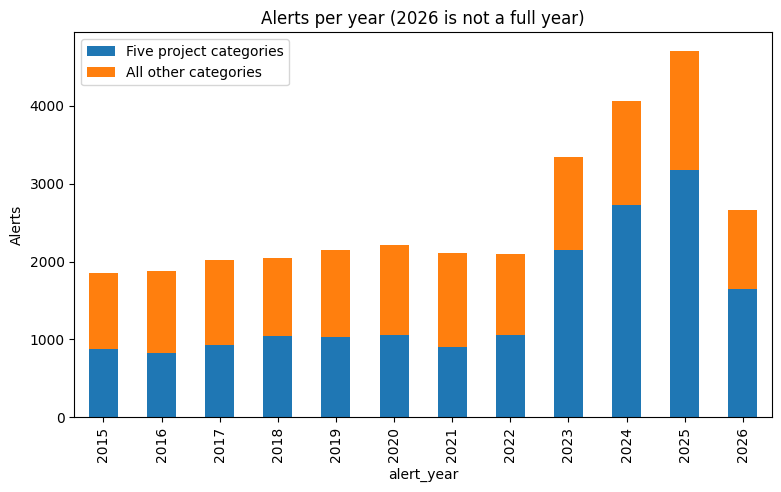

In [85]:
t = df[df["is_target_category"]]            # only the five project categories
all_year = df.groupby("alert_year").size()
target_year = t.groupby("alert_year").size()

pd.DataFrame({"Five project categories": target_year, "All other categories": all_year - target_year}).plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Alerts per year (2026 is not a full year)")
plt.ylabel("Alerts")
plt.savefig("fig1_alerts_per_year.png", bbox_inches="tight")
plt.show()

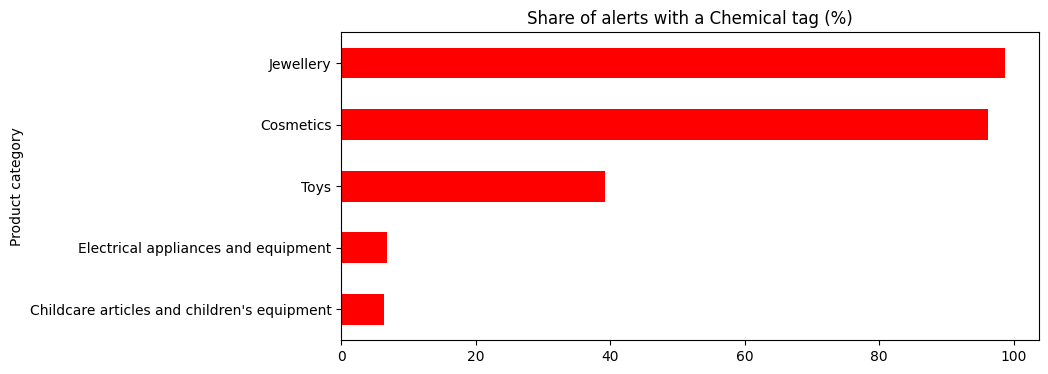

,has_chemical_tag
Product category,
Childcare articles and children's equipment,6.4
Cosmetics,96.2
Electrical appliances and equipment,6.7
Jewellery,98.8
Toys,39.3


In [86]:
chem_share = t.groupby("Product category")["has_chemical_tag"].mean() * 100   # mean of True/False = share of True

chem_share.sort_values().plot(kind="barh", figsize=(9, 4), color="red")
plt.title("Share of alerts with a Chemical tag (%)")
plt.savefig("fig2_chemical_share_by_category.png", bbox_inches="tight")
plt.show()
chem_share.round(1)

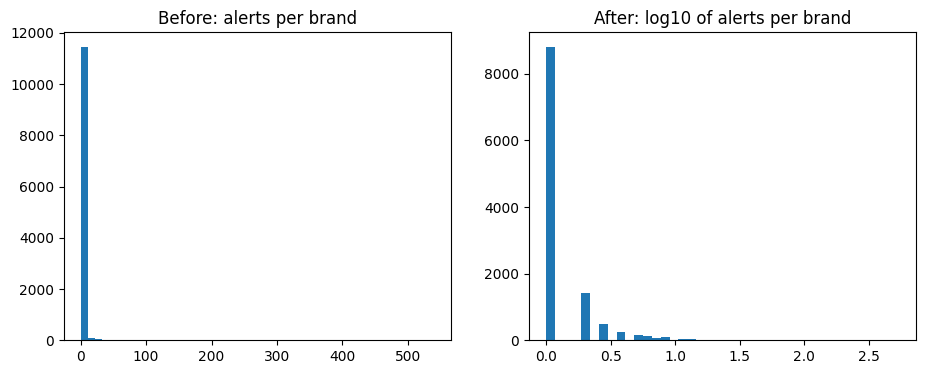

(np.float64(75.58359079986269), np.int64(12))

In [87]:
brand_counts = df[~df["brand_unknown"]]["Product brand"].str.lower().value_counts()   # unknown brands left out

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.hist(brand_counts, bins=50)
plt.title("Before: alerts per brand")
plt.subplot(1, 2, 2)
plt.hist(np.log10(brand_counts), bins=40)     # counts start at 1 so log10 is never a problem
plt.title("After: log10 of alerts per brand")
plt.savefig("fig3_brand_counts.png", bbox_inches="tight")
plt.show()
(brand_counts == 1).mean() * 100, (brand_counts >= 100).sum()   # % of brands seen once, brands seen 100+ times

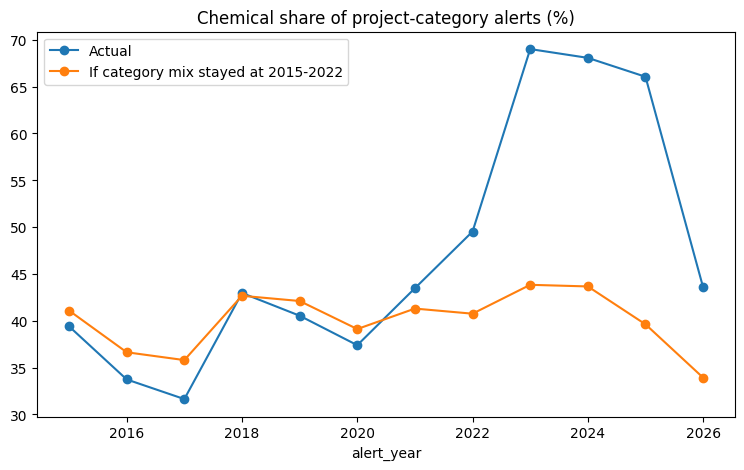

In [88]:
actual = t.groupby("alert_year")["has_chemical_tag"].mean() * 100
rate = t.pivot_table(index="alert_year", columns="Product category", values="has_chemical_tag", aggfunc="mean") * 100   # chemical % inside each category

old_mix = t[t["alert_year"] <= 2022]["Product category"].value_counts(normalize=True)   # category shares in 2015-2022
fixed = (rate * old_mix).sum(axis=1)       # chemical % if the mix had stayed like 2015-2022

pd.DataFrame({"Actual": actual, "If category mix stayed at 2015-2022": fixed}).plot(marker="o", figsize=(9, 5))
plt.title("Chemical share of project-category alerts (%)")
plt.savefig("fig4_chemical_share_actual_vs_fixed.png", bbox_inches="tight")
plt.show()

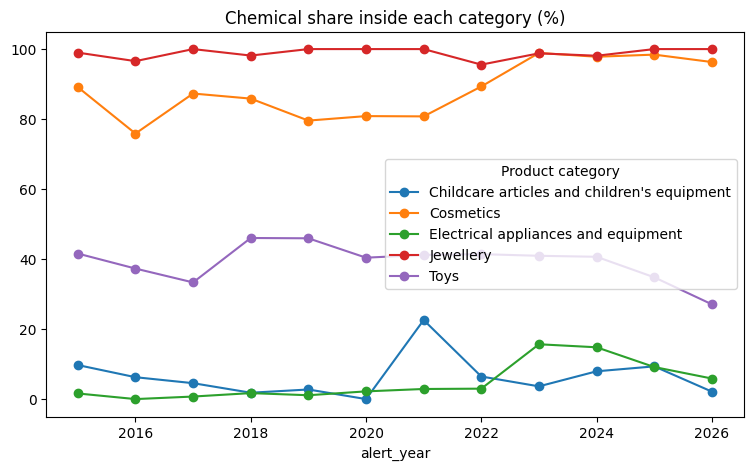

In [89]:
rate.plot(marker="o", figsize=(9, 5))
plt.title("Chemical share inside each category (%)")
plt.savefig("fig5_chemical_share_inside_category.png", bbox_inches="tight")
plt.show()

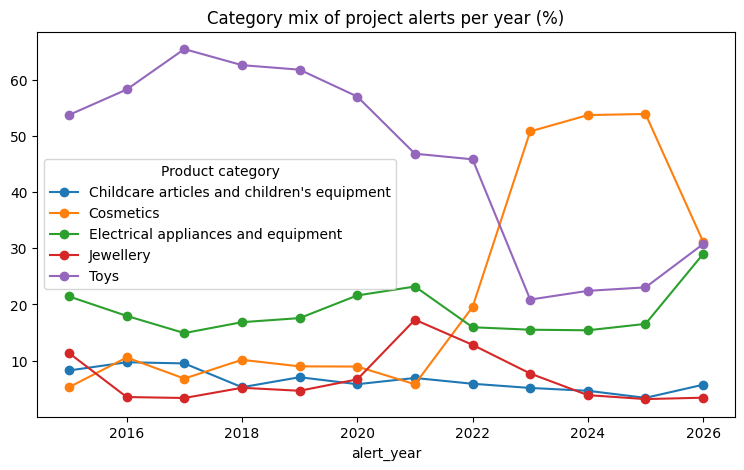

In [90]:
mix = pd.crosstab(t["alert_year"], t["Product category"], normalize="index") * 100   # share of each category per year

mix.plot(marker="o", figsize=(9, 5))
plt.title("Category mix of project alerts per year (%)")
plt.savefig("fig6_category_mix.png", bbox_inches="tight")
plt.show()

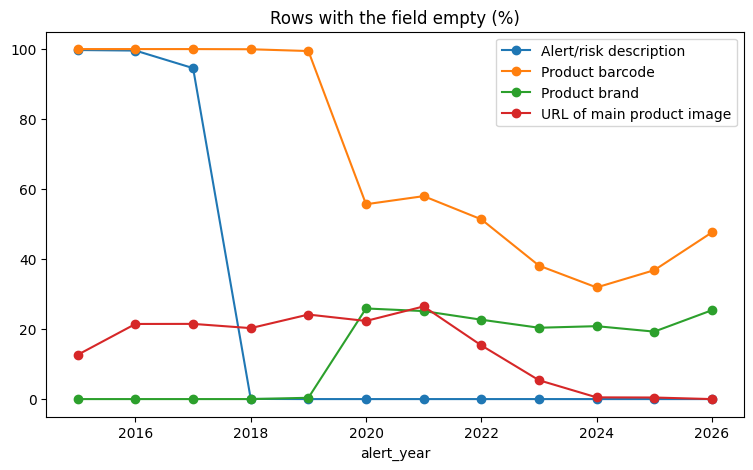

In [91]:
cols = ["Alert/risk description", "Product barcode", "Product brand", "URL of main product image"]
missing = df[cols].isna().groupby(df["alert_year"]).mean() * 100   # % empty per year

missing.plot(marker="o", figsize=(9, 5))
plt.title("Rows with the field empty (%)")
plt.savefig("fig7_missing_by_year.png", bbox_inches="tight")
plt.show()

In [92]:
df.shape

(31140, 45)

In [93]:
df.isna().sum().sort_values(ascending=False).head(10)

,0
URL of the product recall,28667
Product recall code,28427
Product production date,26414
Other countries with similar alerts,21608
Product barcode,19037
Product batch number,18672
Product packaging description,16117
Technical defect,14020
URL of other product images,9607
Alert modification date (week),9447


A data dictionary table. Fill the `meaning` column yourself.

In [117]:
meanings = {
    "Alert/risk level": "how serious the risk is",
    "Type of public": "who the product is for (consumer or professional)",
    "Alert number": "unique id of the alert",
    "Alert submitted by": "country that reported the alert",
    "Country of origin": "country where the product was made",
    "Is the product counterfeit": "whethr the product is fake or not",
    "Alert/risk type": "type of danger",
    "Risk legal provision": "the rule the product failed to meet",
    "Product type": "what kind of product it is",
    "Product name": "name or brand of the product",
}

dictionary = pd.DataFrame({
    "column": df.columns,
    "type": df.dtypes.astype(str).values,
    "empty": df.isna().sum().values,
    "empty_percent": (df.isna().mean() * 100).round(1).values,
    "distinct_values": df.nunique().values,
    "example": [str(df[c].dropna().iloc[0])[:40].replace("\n", " ") for c in df.columns],
})
dictionary["meaning"] = dictionary["column"].map(meanings).fillna("")

dictionary.to_csv("data_dictionary.csv", index=False)
dictionary.head(10)

,column,type,empty,empty_percent,distinct_values,example,meaning
0,Alert/risk level,object,0,0.0,3,Serious risk,how serious the risk is
1,Type of public,object,0,0.0,2,Consumer,who the product is for (consumer or professional)
2,Alert number,object,0,0.0,31140,SR/01140/25,unique id of the alert
3,Alert submitted by,object,0,0.0,31,Italy,country that reported the alert
4,Country of origin,object,0,0.0,109,Unknown,country where the product was made
5,Is the product counterfeit,object,0,0.0,3,Unknown,whethr the product is fake or not
6,Alert/risk type,object,0,0.0,217,Chemical,type of danger
7,Risk legal provision,object,874,2.8,10099,The product does not comply with the Cos,the rule the product failed to meet
8,Product type,object,0,0.0,5825,Deodorant,what kind of product it is
9,Product name,object,4366,14.0,22144,Woody,name or brand of the product
